# TP: CNN LENET 5

In [1]:

# Importation des bibliothèques

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random


DATA_DIR = Path(
    r"C:\Users\hp\.cache\kagglehub\datasets\benaddym\amazigh-handwritten-character-database-amhcd\versions\1"
)


print("Dataset existe :", DATA_DIR.exists())

if DATA_DIR.exists():
    print("Contenu du dataset :")
    for element in DATA_DIR.iterdir():
        print(element.name)

Dataset existe : True
Contenu du dataset :
AMHCD_64
labels


Nombre de classes : 33
ya : 780 images
yab : 780 images
yach : 780 images
yad : 780 images
yadd : 780 images
yae : 780 images
yaf : 780 images
yag : 780 images
yagh : 780 images
yagw : 780 images
yah : 780 images
yahh : 780 images
yaj : 780 images
yak : 780 images
yakw : 780 images
yal : 780 images
yam : 780 images
yan : 780 images
yaq : 780 images
yar : 780 images
yarr : 780 images
yas : 780 images
yass : 780 images
yat : 780 images
yatt : 780 images
yaw : 780 images
yax : 780 images
yay : 780 images
yaz : 780 images
yazz : 780 images
yey : 780 images
yi : 780 images
yu : 780 images


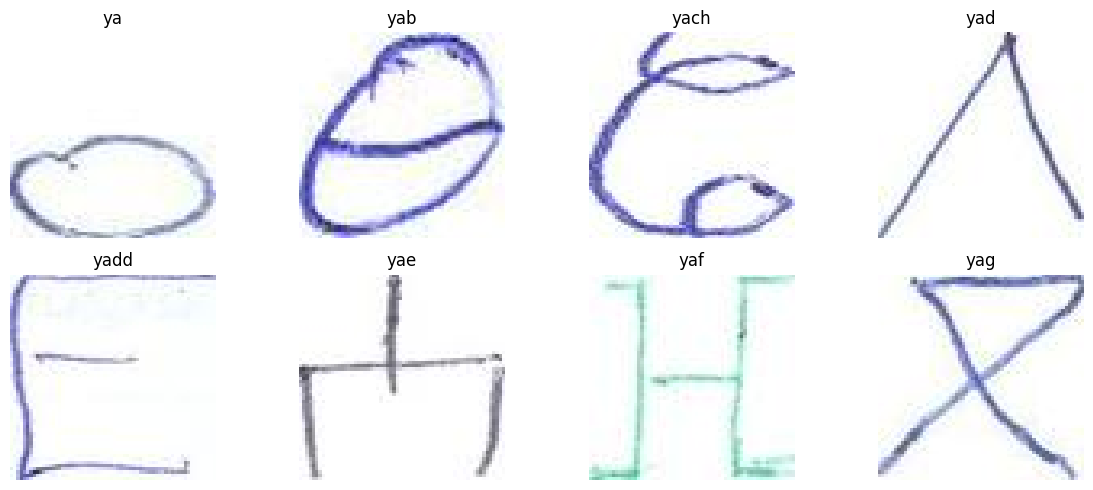

In [2]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random


DATASET_DIR = DATA_DIR / "AMHCD_64" / "AMHCD_64"

classes = sorted([
    dossier for dossier in DATASET_DIR.iterdir()
    if dossier.is_dir()
])

print("Nombre de classes :", len(classes))

# le nombre d'images par classe
for classe in classes:
    images = [
        f for f in classe.iterdir()
        if f.is_file()
        and f.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
    ]
    print(classe.name, ":", len(images), "images")

# exemples des caractères
plt.figure(figsize=(12, 5))

for i in range(min(8, len(classes))):
    images = [
        f for f in classes[i].iterdir()
        if f.is_file()
        and f.suffix.lower() in [".png", ".jpg", ".jpeg", ".bmp"]
    ]

    if images:
        image_path = random.choice(images)
        image = Image.open(image_path)

        plt.subplot(2, 4, i + 1)
        plt.imshow(image)
        plt.title(classes[i].name)
        plt.axis("off")

plt.tight_layout()
plt.show()

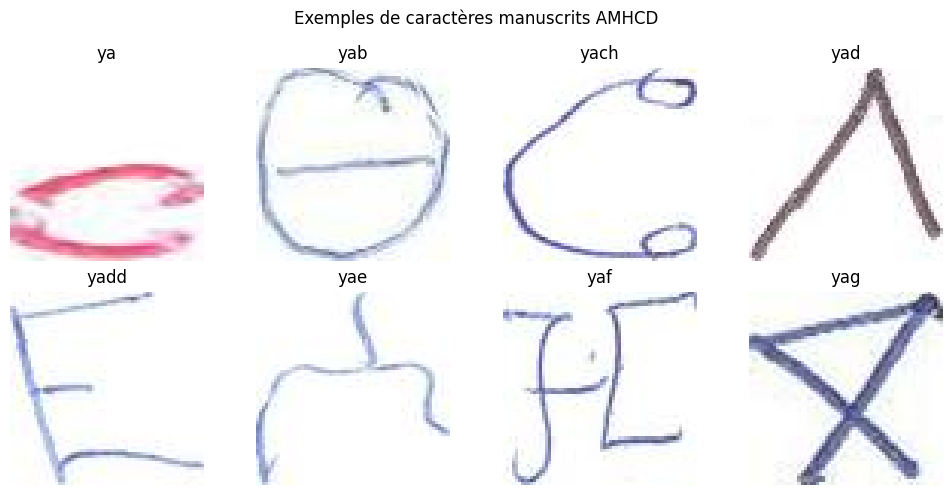

In [3]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

SEED = 42
random.seed(SEED)

FIG_DIR = Path("resultats_figures")
FIG_DIR.mkdir(exist_ok=True)

fig, axes = plt.subplots(2, 4, figsize=(10, 5))

for i, ax in enumerate(axes.flat):
    classe = classes[i]
    fichiers = [
        f for f in classe.iterdir()
        if f.is_file() and f.suffix.lower()
        in [".png", ".jpg", ".jpeg", ".bmp"]
    ]

    image_path = random.choice(fichiers)
    image = Image.open(image_path)

    ax.imshow(image)
    ax.set_title(classe.name)
    ax.axis("off")

fig.suptitle("Exemples de caractères manuscrits AMHCD")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure_01_exemples_amhcd.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [4]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

print("PyTorch :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("NumPy :", np.__version__)
print("Toutes les bibliothèques sont importées avec succès.")

PyTorch : 2.12.0+cpu
Torchvision : 0.27.0+cpu
NumPy : 2.4.3
Toutes les bibliothèques sont importées avec succès.


In [5]:


from pathlib import Path

DATA_DIR = Path(
    r"C:\Users\hp\.cache\kagglehub\datasets\benaddym\amazigh-handwritten-character-database-amhcd\versions\1"
)

DATASET_DIR = DATA_DIR / "AMHCD_64" / "AMHCD_64"

print("Dataset existe :", DATASET_DIR.exists())

if DATASET_DIR.exists():
    classes = sorted([
        dossier for dossier in DATASET_DIR.iterdir()
        if dossier.is_dir()
    ])
    print("Nombre de classes :", len(classes))

Dataset existe : True
Nombre de classes : 33


In [6]:

# pretraitement et chargement des images

from torchvision import datasets, transforms


transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])


dataset = datasets.ImageFolder(
    root=str(DATASET_DIR),
    transform=transform
)


print("Nombre total d'images :", len(dataset))
print("Nombre de classes :", len(dataset.classes))
print("Dimensions des images :", dataset[0][0].shape)
print("Nombre d'images par classe :",
      len(dataset) // len(dataset.classes))


assert len(dataset) == 25740
assert len(dataset.classes) == 33
assert dataset[0][0].shape == (1, 32, 32)

print("Pretraitement termine avec succes.")

Nombre total d'images : 25740
Nombre de classes : 33
Dimensions des images : torch.Size([1, 32, 32])
Nombre d'images par classe : 780
Pretraitement termine avec succes.


In [7]:

# division de dataset en Train, Validation ,Test

from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from collections import Counter

SEED = 42
BATCH_SIZE = 64

# Indices et labels de toutes les images
indices = list(range(len(dataset)))
labels = dataset.targets

# Premiere division : 70% Train et 30% temporaire
train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=SEED,
    stratify=labels
)

# Deuxieme division : 15% Validation et 15% Test
val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=SEED,
    stratify=[labels[i] for i in temp_idx]
)

# Creation des trois sous-datasets
train_dataset = Subset(dataset, train_idx)
val_dataset = Subset(dataset, val_idx)
test_dataset = Subset(dataset, test_idx)

# Creation des DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE,
    shuffle=True, num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)

test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE,
    shuffle=False, num_workers=0
)


print("Train :", len(train_dataset), "images")
print("Validation :", len(val_dataset), "images")
print("Test :", len(test_dataset), "images")
print("Total :", len(train_dataset) + len(val_dataset) + len(test_dataset))

# Verification
assert len(train_dataset) == 18018
assert len(val_dataset) == 3861
assert len(test_dataset) == 3861

print("Division terminee avec succes.")

Train : 18018 images
Validation : 3861 images
Test : 3861 images
Total : 25740
Division terminee avec succes.


In [8]:

#  implementation de LeNet-5

import torch
import torch.nn as nn


def creer_convolution(in_channels, out_channels, kernel_size):
    return nn.Conv2d(
        in_channels=in_channels,
        out_channels=out_channels,
        kernel_size=kernel_size
    )

# Fonction parametrable pour le pooling moyen
def creer_pooling(kernel_size=2, stride=2):
    return nn.AvgPool2d(
        kernel_size=kernel_size,
        stride=stride
    )

# Fonction parametrable pour une couche fully connected
def creer_couche_dense(in_features, out_features):
    return nn.Linear(in_features, out_features)


class LeNet5(nn.Module):
    def __init__(self, num_classes=33):
        super().__init__()

        # C1 : convolution 1 -> 6
        self.c1 = creer_convolution(1, 6, 5)

        # S2 : average pooling
        self.s2 = creer_pooling(2, 2)

        # C3 : convolution 6 -> 16
        self.c3 = creer_convolution(6, 16, 5)

        # S4 : average pooling
        self.s4 = creer_pooling(2, 2)

        # C5, F6 et couche de sortie
        self.c5 = creer_couche_dense(16 * 5 * 5, 120)
        self.f6 = creer_couche_dense(120, 84)
        self.sortie = creer_couche_dense(84, num_classes)

        self.tanh = nn.Tanh()

    def forward(self, x):
        # C1 et S2
        x = self.tanh(self.c1(x))
        x = self.s2(x)

        # C3 et S4
        x = self.tanh(self.c3(x))
        x = self.s4(x)

        # Transformation en vecteur
        x = torch.flatten(x, start_dim=1)

        # C5, F6 et sortie
        x = self.tanh(self.c5(x))
        x = self.tanh(self.f6(x))
        x = self.sortie(x)

        return x


# Creation du modele
model = LeNet5(num_classes=33)

print(model)

LeNet5(
  (c1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (s2): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (s4): AvgPool2d(kernel_size=2, stride=2, padding=0)
  (c5): Linear(in_features=400, out_features=120, bias=True)
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (sortie): Linear(in_features=84, out_features=33, bias=True)
  (tanh): Tanh()
)


In [9]:

# Test des dimensions en entree et en sortie

images_test = torch.randn(2, 1, 32, 32)

with torch.no_grad():
    predictions = model(images_test)

print("Entree :", images_test.shape)
print("Sortie :", predictions.shape)

assert predictions.shape == (2, 33)

print("Architecture LeNet-5 validee.")

Entree : torch.Size([2, 1, 32, 32])
Sortie : torch.Size([2, 33])
Architecture LeNet-5 validee.


In [10]:

# fonction d'entrainement et d'evaluation

import torch
import torch.nn as nn

# Fonction pour calculer la perte et l'accuracy
def evaluer_modele(model, data_loader, criterion, device):
    model.eval()
    perte_totale = 0.0
    bonnes_predictions = 0
    total = 0

    with torch.no_grad():
        for images, labels_batch in data_loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)

            sorties = model(images)
            perte = criterion(sorties, labels_batch)

            perte_totale += perte.item() * images.size(0)
            predictions = sorties.argmax(dim=1)
            bonnes_predictions += (predictions == labels_batch).sum().item()
            total += labels_batch.size(0)

    perte_moyenne = perte_totale / total
    accuracy = 100.0 * bonnes_predictions / total

    return perte_moyenne, accuracy


def entrainer_epoch(model, data_loader, criterion, optimizer, device):
    model.train()
    perte_totale = 0.0
    bonnes_predictions = 0
    total = 0

    for images, labels_batch in data_loader:
        images = images.to(device)
        labels_batch = labels_batch.to(device)

        # Remise a zero des gradients
        optimizer.zero_grad()

        # Propagation avant
        sorties = model(images)
        perte = criterion(sorties, labels_batch)

        # Retropropagation et mise a jour des poids
        perte.backward()
        optimizer.step()

        perte_totale += perte.item() * images.size(0)
        predictions = sorties.argmax(dim=1)
        bonnes_predictions += (predictions == labels_batch).sum().item()
        total += labels_batch.size(0)

    return perte_totale / total, 100.0 * bonnes_predictions / total


# Utilisation du CPU
device = torch.device("cpu")
criterion = nn.CrossEntropyLoss()

print("Device :", device)
print("Fonctions d'entrainement et d'evaluation pretes.")

Device : cpu
Fonctions d'entrainement et d'evaluation pretes.


In [11]:

# Teste une seule epoque avec Adam

model_test = LeNet5(num_classes=33).to(device)
optimizer_test = torch.optim.Adam(model_test.parameters(), lr=0.001)

loss_train, acc_train = entrainer_epoch(
    model_test, train_loader, criterion, optimizer_test, device
)

loss_val, acc_val = evaluer_modele(
    model_test, val_loader, criterion, device
)

print(f"Train - Loss : {loss_train:.4f}, Accuracy : {acc_train:.2f}%")
print(f"Validation - Loss : {loss_val:.4f}, Accuracy : {acc_val:.2f}%")
print("Test d'entrainement termine.")

Train - Loss : 1.4896, Accuracy : 65.45%
Validation - Loss : 0.6179, Accuracy : 85.42%
Test d'entrainement termine.


In [12]:

# entrainement 

import time
import copy

def entrainer_modele(nom_optimiseur, epochs=10, lr=0.001):
    # Initialisation d'un nouveau modele pour chaque optimiseur
    reseau = LeNet5(num_classes=33).to(device)

    if nom_optimiseur == "SGD":
        optimiseur = torch.optim.SGD(
            reseau.parameters(),
            lr=lr,
            momentum=0.9
        )
    elif nom_optimiseur == "Adam":
        optimiseur = torch.optim.Adam(
            reseau.parameters(),
            lr=lr
        )
    else:
        raise ValueError("Optimiseur non reconnu.")

    historique = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    meilleure_accuracy = 0.0
    meilleur_etat = copy.deepcopy(reseau.state_dict())

    debut = time.time()

    for epoch in range(epochs):
        loss_train, acc_train = entrainer_epoch(
            reseau, train_loader, criterion, optimiseur, device
        )

        loss_val, acc_val = evaluer_modele(
            reseau, val_loader, criterion, device
        )

        historique["train_loss"].append(loss_train)
        historique["train_acc"].append(acc_train)
        historique["val_loss"].append(loss_val)
        historique["val_acc"].append(acc_val)

        # Sauvegarder le meilleur modele selon la validation
        if acc_val > meilleure_accuracy:
            meilleure_accuracy = acc_val
            meilleur_etat = copy.deepcopy(reseau.state_dict())

        print(
            f"{nom_optimiseur} | Epoch {epoch + 1}/{epochs} "
            f"| Train Loss: {loss_train:.4f} "
            f"| Train Acc: {acc_train:.2f}% "
            f"| Val Loss: {loss_val:.4f} "
            f"| Val Acc: {acc_val:.2f}%"
        )

    # Restaurer le meilleur modele selon la validation
    reseau.load_state_dict(meilleur_etat)

    duree = time.time() - debut
    print(f"Duree {nom_optimiseur}: {duree / 60:.1f} minutes")

    return reseau, historique


print("Fonction d'entrainement complet prete.")

Fonction d'entrainement complet prete.


In [13]:

#  comparaison de SGD et Adam

EPOCHS = 10

model_sgd, historique_sgd = entrainer_modele(
    nom_optimiseur="SGD",
    epochs=EPOCHS,
    lr=0.01
)

model_adam, historique_adam = entrainer_modele(
    nom_optimiseur="Adam",
    epochs=EPOCHS,
    lr=0.001
)

print("Les deux entrainements sont termines.")

SGD | Epoch 1/10 | Train Loss: 3.3490 | Train Acc: 13.03% | Val Loss: 2.5622 | Val Acc: 32.84%
SGD | Epoch 2/10 | Train Loss: 1.2796 | Train Acc: 72.55% | Val Loss: 0.6882 | Val Acc: 83.94%
SGD | Epoch 3/10 | Train Loss: 0.5263 | Train Acc: 87.77% | Val Loss: 0.4145 | Val Acc: 89.87%
SGD | Epoch 4/10 | Train Loss: 0.3495 | Train Acc: 91.71% | Val Loss: 0.3045 | Val Acc: 92.20%
SGD | Epoch 5/10 | Train Loss: 0.2593 | Train Acc: 93.68% | Val Loss: 0.2383 | Val Acc: 93.78%
SGD | Epoch 6/10 | Train Loss: 0.1998 | Train Acc: 95.17% | Val Loss: 0.1843 | Val Acc: 94.98%
SGD | Epoch 7/10 | Train Loss: 0.1603 | Train Acc: 96.18% | Val Loss: 0.1574 | Val Acc: 95.83%
SGD | Epoch 8/10 | Train Loss: 0.1343 | Train Acc: 96.71% | Val Loss: 0.1403 | Val Acc: 96.04%
SGD | Epoch 9/10 | Train Loss: 0.1109 | Train Acc: 97.47% | Val Loss: 0.1176 | Val Acc: 96.92%
SGD | Epoch 10/10 | Train Loss: 0.0967 | Train Acc: 97.76% | Val Loss: 0.1187 | Val Acc: 96.87%
Duree SGD: 9.4 minutes
Adam | Epoch 1/10 | Train 

In [14]:
from pathlib import Path
import matplotlib.pyplot as plt

# Dossier de sauvegarde des figures
FIG_DIR = Path("resultats_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Dossier des figures :", FIG_DIR.resolve())

Dossier des figures : D:\FPO\Master S2\DL\TPs-DL\Nouveau dossier\TP_CNN LENET 5\resultats_figures


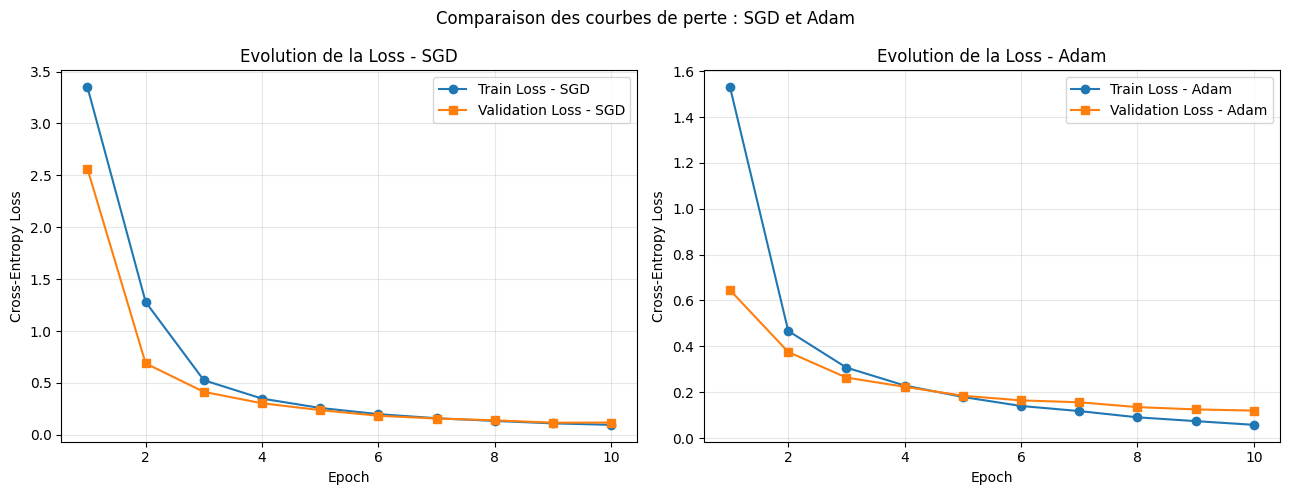

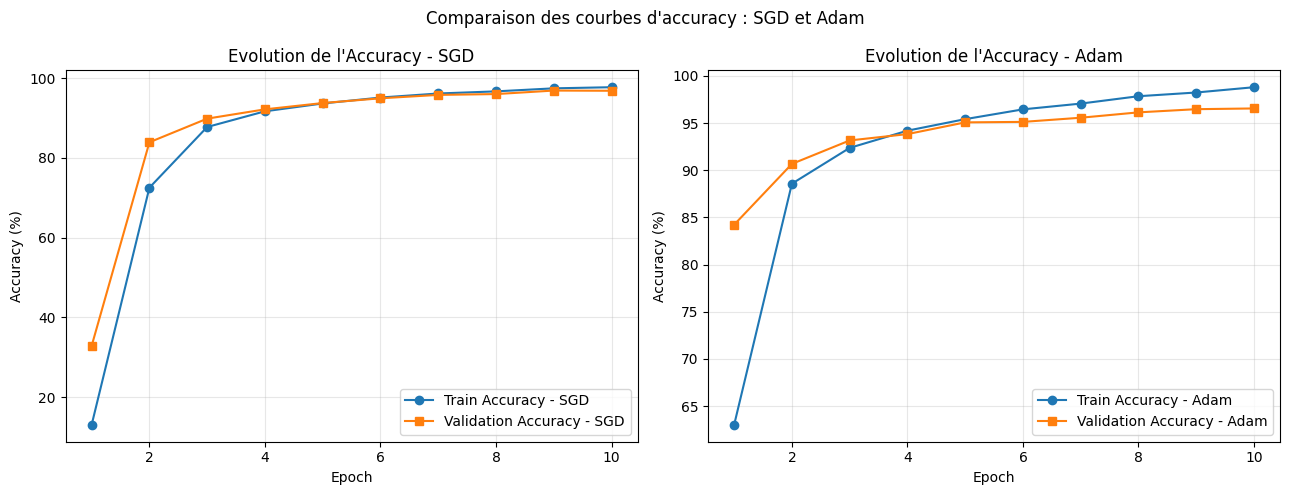

Figures 2 et 3 enregistrees dans : D:\FPO\Master S2\DL\TPs-DL\Nouveau dossier\TP_CNN LENET 5\resultats_figures


In [15]:

#  visualisation des courbes d'apprentissage

# Figure 2 : courbes de perte (Loss)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
epochs = range(1, EPOCHS + 1)

# Loss - SGD
axes[0].plot(epochs, historique_sgd["train_loss"], marker="o",
             label="Train Loss - SGD")
axes[0].plot(epochs, historique_sgd["val_loss"], marker="s",
             label="Validation Loss - SGD")
axes[0].set_title("Evolution de la Loss - SGD")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-Entropy Loss")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss - Adam
axes[1].plot(epochs, historique_adam["train_loss"], marker="o",
             label="Train Loss - Adam")
axes[1].plot(epochs, historique_adam["val_loss"], marker="s",
             label="Validation Loss - Adam")
axes[1].set_title("Evolution de la Loss - Adam")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Cross-Entropy Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle("Comparaison des courbes de perte : SGD et Adam")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure_02_courbes_loss.png",
            dpi=300, bbox_inches="tight")
plt.show()


# Figure 3 : courbes d'accuracy
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Accuracy - SGD
axes[0].plot(epochs, historique_sgd["train_acc"], marker="o",
             label="Train Accuracy - SGD")
axes[0].plot(epochs, historique_sgd["val_acc"], marker="s",
             label="Validation Accuracy - SGD")
axes[0].set_title("Evolution de l'Accuracy - SGD")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy (%)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Accuracy - Adam
axes[1].plot(epochs, historique_adam["train_acc"], marker="o",
             label="Train Accuracy - Adam")
axes[1].plot(epochs, historique_adam["val_acc"], marker="s",
             label="Validation Accuracy - Adam")
axes[1].set_title("Evolution de l'Accuracy - Adam")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

fig.suptitle("Comparaison des courbes d'accuracy : SGD et Adam")
fig.tight_layout()
fig.savefig(FIG_DIR / "figure_03_courbes_accuracy.png",
            dpi=300, bbox_inches="tight")
plt.show()

print("Figures 2 et 3 enregistrees dans :", FIG_DIR.resolve())

In [16]:

# Choisir le modèle ayant la meilleure accuracy de validation
model_final = model_adam

# Évaluation finale sur les données de test
loss_test, acc_test = evaluer_modele(
    model_final, test_loader, criterion, device
)

print(f"Test Loss : {loss_test:.4f}")
print(f"Test Accuracy : {acc_test:.2f}%")

Test Loss : 0.1184
Test Accuracy : 96.63%


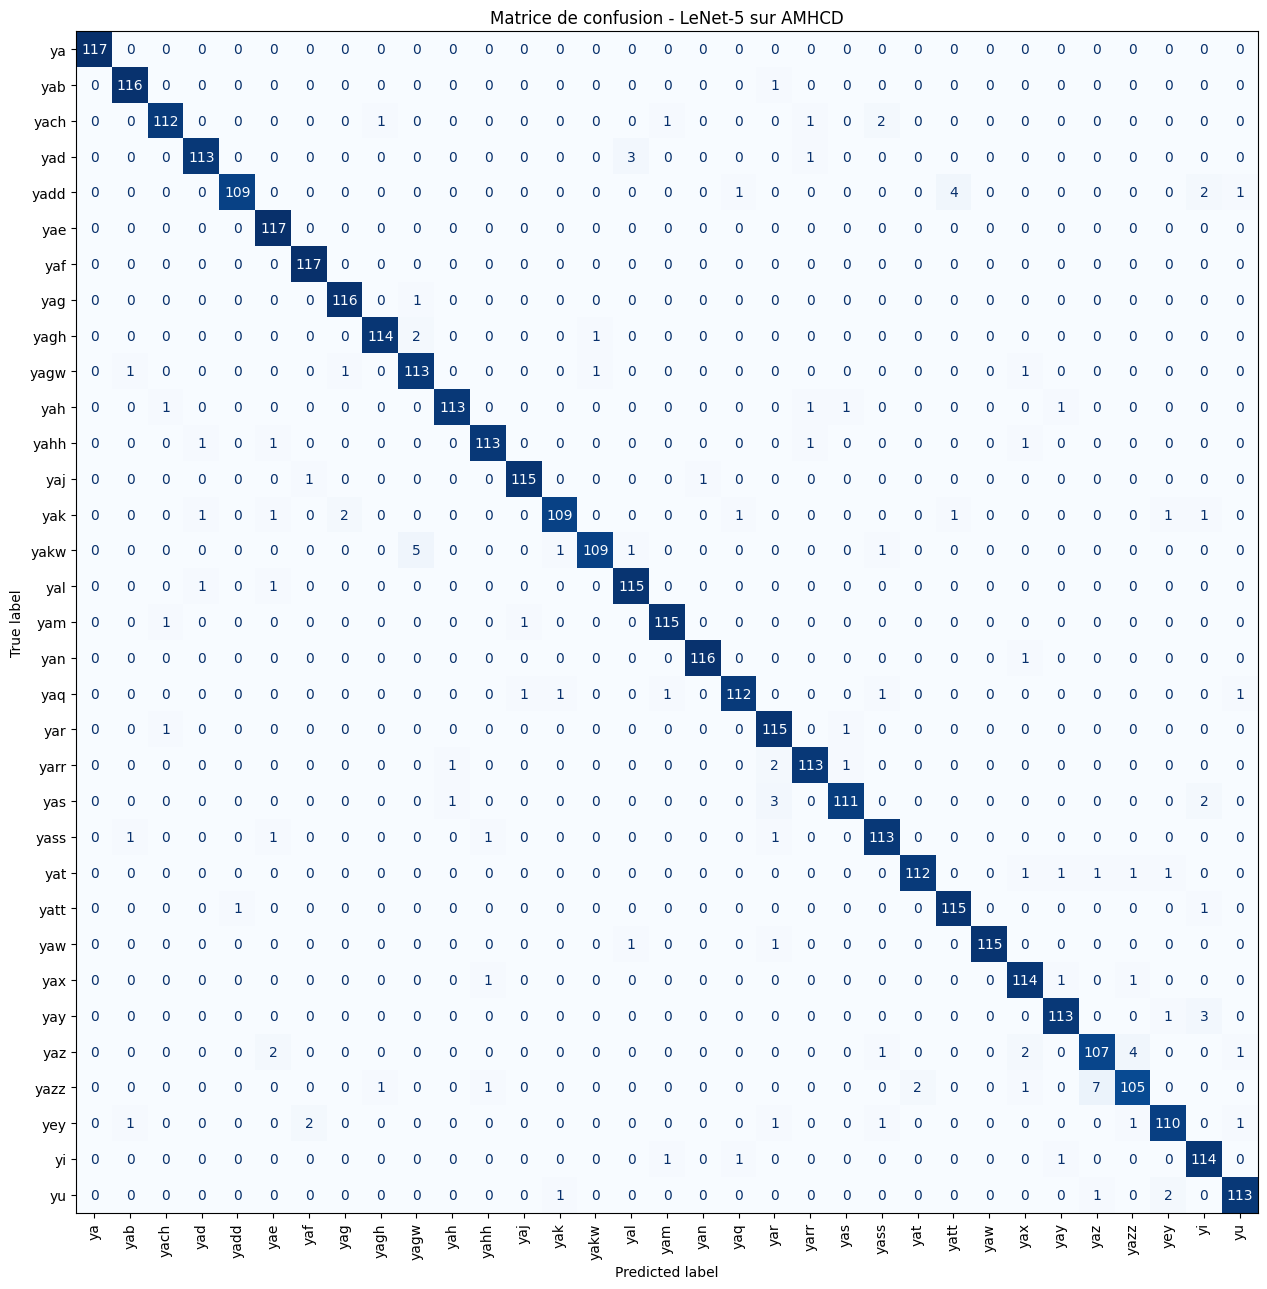

Figure 4 enregistree dans : D:\FPO\Master S2\DL\TPs-DL\Nouveau dossier\TP_CNN LENET 5\resultats_figures\figure_04_matrice_confusion.png
Nombre total de tests : 3861
Predictions correctes : 3731


In [17]:
#matrice de confusion
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Recuperer les vraies classes et les predictions
model_final.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for images, labels_batch in test_loader:
        images = images.to(device)

        sorties = model_final(images)
        predictions = sorties.argmax(dim=1)

        y_true.extend(labels_batch.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calculer la matrice de confusion
classes = dataset.classes
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(classes)))
)

# Afficher et sauvegarder la figure
fig, ax = plt.subplots(figsize=(15, 13))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=classes
)

disp.plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title("Matrice de confusion - LeNet-5 sur AMHCD")
fig.tight_layout()

chemin = FIG_DIR / "figure_04_matrice_confusion.png"
fig.savefig(chemin, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 4 enregistree dans :", chemin.resolve())
print("Nombre total de tests :", cm.sum())
print("Predictions correctes :", np.trace(cm))

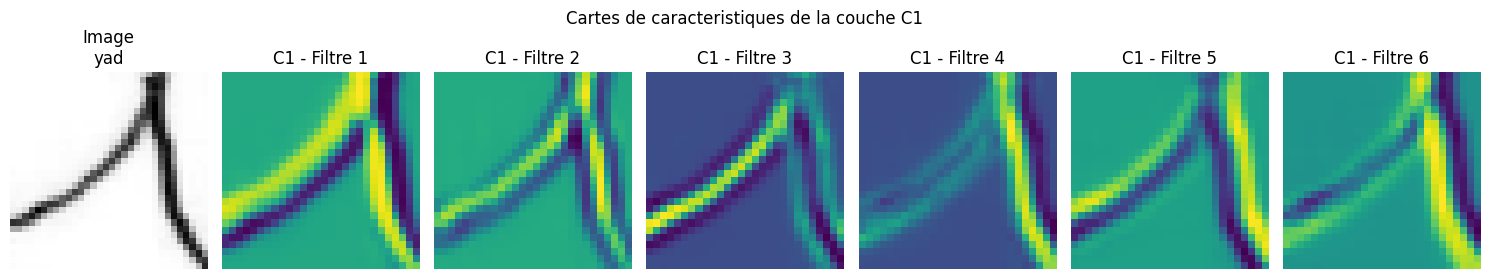

Figure 5 enregistree dans : D:\FPO\Master S2\DL\TPs-DL\Nouveau dossier\TP_CNN LENET 5\resultats_figures\figure_05_feature_maps.png


In [18]:
#figure:Feature maps 

import matplotlib.pyplot as plt
import torch

# Recuperer une image de test
image, label = test_dataset[0]
image_batch = image.unsqueeze(0).to(device)

# Extraire les cartes de caracteristiques de C1
model_final.eval()

with torch.no_grad():
    feature_maps = model_final.tanh(model_final.c1(image_batch))

# Afficher l'image originale et les 6 cartes de C1
fig, axes = plt.subplots(1, 7, figsize=(15, 3))

# Restaurer l'image pour l'affichage
image_display = image.squeeze(0).cpu().numpy()
image_display = (image_display + 1) / 2

axes[0].imshow(image_display, cmap="gray")
axes[0].set_title(f"Image\n{classes[label]}")
axes[0].axis("off")

for i in range(6):
    axes[i + 1].imshow(
        feature_maps[0, i].cpu().numpy(),
        cmap="viridis"
    )
    axes[i + 1].set_title(f"C1 - Filtre {i + 1}")
    axes[i + 1].axis("off")

fig.suptitle("Cartes de caracteristiques de la couche C1")
fig.tight_layout()

chemin = FIG_DIR / "figure_05_feature_maps.png"
fig.savefig(chemin, dpi=300, bbox_inches="tight")
plt.show()

print("Figure 5 enregistree dans :", chemin.resolve())

# Calculer les métriques: Precision, Recall et F1-score 

In [19]:

import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (
    classification_report,
    precision_recall_fscore_support
)


model_final.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        sorties = model_final(images)
        predictions = sorties.argmax(dim=1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calculer les métriques pour les 33 classes
classes = dataset.classes

precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    zero_division=0
)


df_metrics = pd.DataFrame({
    "Classe": classes,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Nombre_images": support
})


print("Rapport de classification sur le jeu de test :")
print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(classes))),
    target_names=classes,
    digits=4,
    zero_division=0
))


FIG_DIR.mkdir(parents=True, exist_ok=True)
df_metrics.to_csv(
    FIG_DIR / "rapport_classification_test.csv",
    index=False
)

print("Fichier CSV sauvegardé avec succès.")

Rapport de classification sur le jeu de test :
              precision    recall  f1-score   support

          ya     1.0000    1.0000    1.0000       117
         yab     0.9748    0.9915    0.9831       117
        yach     0.9739    0.9573    0.9655       117
         yad     0.9741    0.9658    0.9700       117
        yadd     0.9909    0.9316    0.9604       117
         yae     0.9512    1.0000    0.9750       117
         yaf     0.9750    1.0000    0.9873       117
         yag     0.9748    0.9915    0.9831       117
        yagh     0.9828    0.9744    0.9785       117
        yagw     0.9339    0.9658    0.9496       117
         yah     0.9826    0.9658    0.9741       117
        yahh     0.9741    0.9658    0.9700       117
         yaj     0.9829    0.9829    0.9829       117
         yak     0.9732    0.9316    0.9520       117
        yakw     0.9820    0.9316    0.9561       117
         yal     0.9583    0.9829    0.9705       117
         yam     0.9746    0.9829 

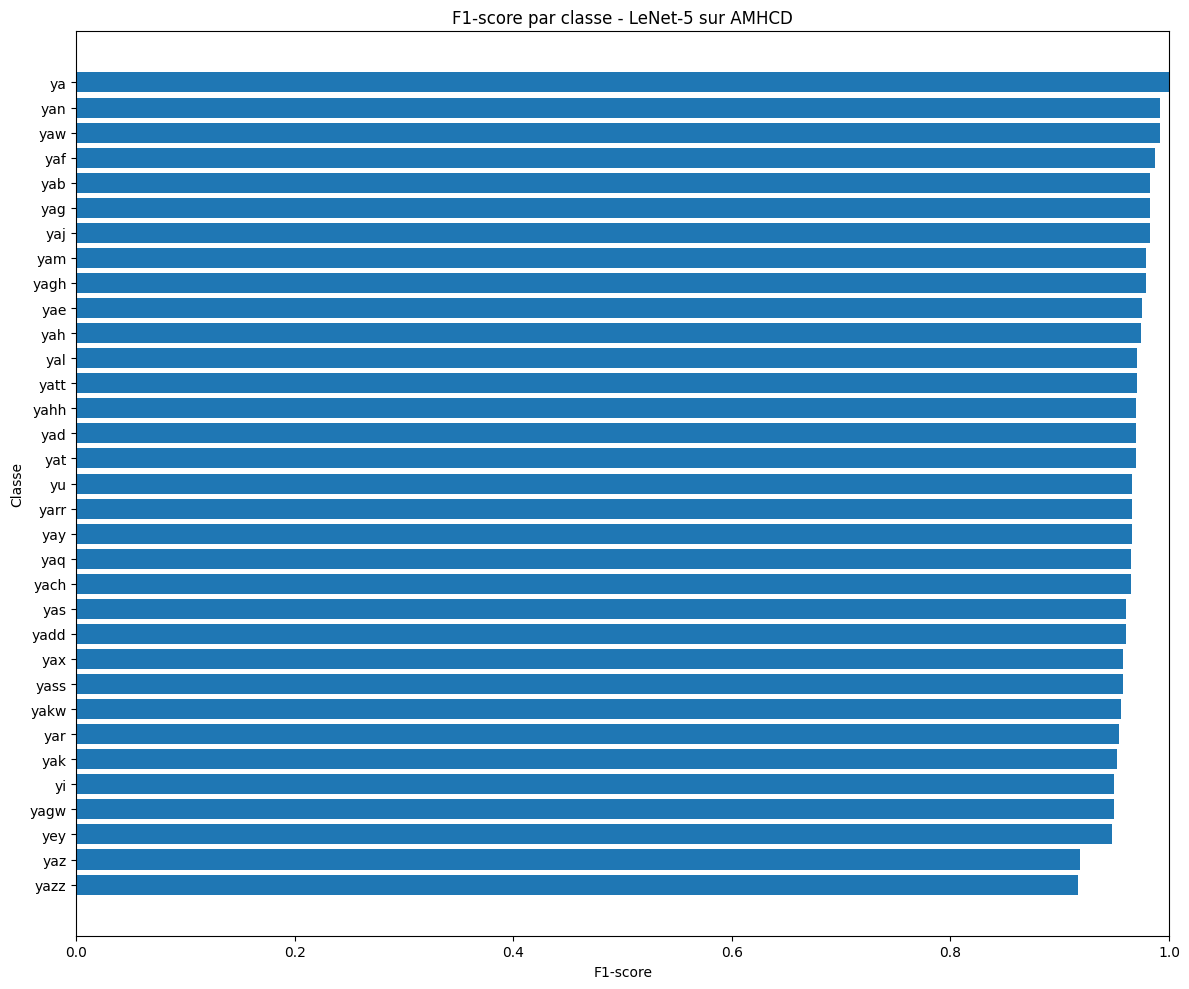

Figure 6 sauvegardée avec succès.


In [20]:

# Figure 6 : F1-score par classe

df_plot = df_metrics.sort_values("F1-score")

plt.figure(figsize=(12, 10))
plt.barh(df_plot["Classe"], df_plot["F1-score"])
plt.xlabel("F1-score")
plt.ylabel("Classe")
plt.title("F1-score par classe - LeNet-5 sur AMHCD")
plt.xlim(0, 1)
plt.tight_layout()

plt.savefig(
    FIG_DIR / "figure_06_f1_par_classe.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figure 6 sauvegardée avec succès.")

# Visualisation des Feature Maps de la couche C3

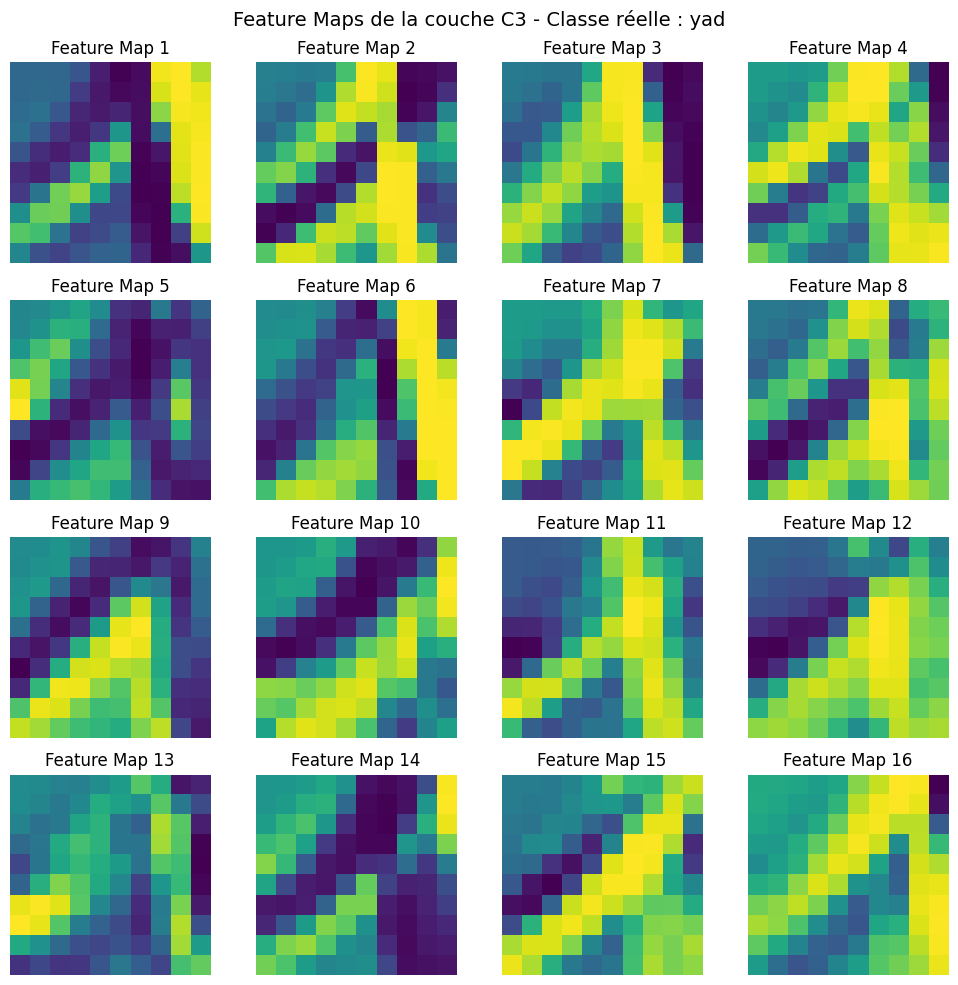

Figure 7 sauvegardée avec succès.
Dimensions des Feature Maps C3 : (16, 10, 10)


In [21]:

import torch
import matplotlib.pyplot as plt
import math

# Mettre le modèle en mode évaluation
model_final.eval()

# Prendre une image du jeu de test
images, labels = next(iter(test_loader))
image = images[0:1].to(device)
vraie_classe = dataset.classes[labels[0].item()]

# Extraire les activations de C1 et C3
with torch.no_grad():
    activation_c1 = model_final.tanh(model_final.c1(image))
    activation_s2 = model_final.s2(activation_c1)
    activation_c3 = model_final.tanh(model_final.c3(activation_s2))

# Convertir en tableaux NumPy
feature_maps = activation_c3[0].cpu().numpy()

# Afficher les 16 cartes de caractéristiques
fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.set_title(f"Feature Map {i + 1}")
    ax.axis("off")

fig.suptitle(
    f"Feature Maps de la couche C3 - Classe réelle : {vraie_classe}",
    fontsize=14
)
plt.tight_layout()


plt.savefig(
    FIG_DIR / "figure_07_feature_maps_C3.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figure 7 sauvegardée avec succès.")
print("Dimensions des Feature Maps C3 :", feature_maps.shape)

# Comparaison entre SGD et Adam

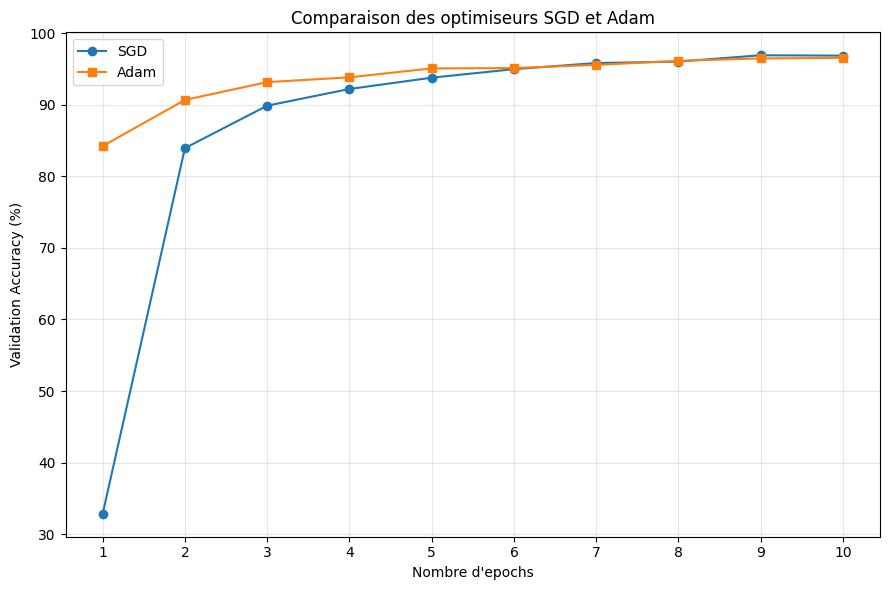

Meilleure Validation Accuracy SGD  : 96.92 %
Meilleure Validation Accuracy Adam : 96.56 %
Figure 8 sauvegardée avec succès.


In [24]:

# Comparaison des optimiseurs SGD et Adam

import matplotlib.pyplot as plt

epochs_sgd = range(1, len(historique_sgd["val_acc"]) + 1)
epochs_adam = range(1, len(historique_adam["val_acc"]) + 1)

plt.figure(figsize=(9, 6))

plt.plot(
    epochs_sgd,
    historique_sgd["val_acc"],
    marker="o",
    label="SGD"
)

plt.plot(
    epochs_adam,
    historique_adam["val_acc"],
    marker="s",
    label="Adam"
)

plt.xlabel("Nombre d'epochs")
plt.ylabel("Validation Accuracy (%)")
plt.title("Comparaison des optimiseurs SGD et Adam")
plt.xticks(list(epochs_sgd))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

# Sauvegarder la figure
plt.savefig(
    FIG_DIR / "figure_08_comparaison_SGD_Adam.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Afficher les meilleures performances de validation
meilleur_sgd = max(historique_sgd["val_acc"])
meilleur_adam = max(historique_adam["val_acc"])

print(f"Meilleure Validation Accuracy SGD  : {meilleur_sgd:.2f} %")
print(f"Meilleure Validation Accuracy Adam : {meilleur_adam:.2f} %")
print("Figure 8 sauvegardée avec succès.")